# a prototyping notebook for parallelization

In [4]:
import torch

from em1d.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [5]:
def colecole(rho_o, m, tau, c, omega):
    tmp = 1.+(1j*omega*tau)**c
    tmp = 1. - 1./tmp
    tmp = 1. - m*tmp
    rho = rho_o*tmp
    return rho

class IPForward:
    def __init__(self, source, receiver, times=tc.logspace(1e-5, 1e-2, 31)):
        self.source = source
        self.receiver = receiver
        self.times = torch.tensor(times)
        self.lgtimes = torch.log(self.times)

        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.r = precalcHankel1.range(self.rmin, self.rmax)[0].numpy()
        self.sofr = torch.tensor(self.source.s_of_r(self.receiver, self.r), dtype=torch.complex128)
        self.dz = torch.tensor(self.receiver.z+self.source.z[0])# tentative solution

    def forward(self):
        def frq_integrand(omega):
            omega = omega[None,:,None]
            self.sigma = 1./colecole(self.rho, self.m, self.tau, self.c, omega)
            def hankel_integrand(wave_length):
                lmb = wave_length[None, None, :]
                tmp_u0 = u0(omega, lmb)
                intg = (torch.exp(-tmp_u0*self.dz)*rte(self.sigma, self.thick, omega, lmb))*lmb**2 / tmp_u0
                return torch.squeeze(intg/(1j*omega))
            hkl = Hankel(hankel_integrand, 1)
            r, hr = hkl.range(self.rmin, self.rmax)
            hr /= r[:,None,None]
            return hr.T@self.sofr
        f_t=Fourier(frq_integrand)
        t,dbdt = f_t.range(self.times[0], self.times[-1])
        return t, dbdt

    def __call__(self, rho, m, tau, c, thickness):
        self.rho   = torch.tensor(rho, dtype=torch.complex128)[...,None,None]
        self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
        self.m     = torch.tensor(m, dtype=torch.complex128)[..., None,None]
        self.tau   = torch.tensor(tau, dtype=torch.complex128)[..., None,None]
        self.c     = torch.tensor(c, dtype=torch.complex128)[..., None,None]
        return self.forward()

In [7]:
lp = Loop.circle(6, z=20)
rx = Receiver(z=25)
times = np.logspace(-5,-2, 31)

In [14]:
n_forwards = np.logspace(0, 2, 9).astype(int)
t_forwards = np.zeros(n_forwards.shape)

from time import perf_counter as timer

for i_nf,nf in enumerate(n_forwards):
    rho = 1./(torch.tensor([0.1, 1, 0.1, 0.3, 10, 25])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:])
    thick = torch.tensor([40, 40, 40, 40, 40])[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    m     = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    tau   = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]
    c     = torch.tensor([0.1]*6)[:,None] + torch.tensor(np.arange(nf)*0.1)[None,:]

    fwr = IPForward(lp, rx, times)
    bt = timer()
    for i in range(5):
        t1,dbdt1 = fwr(rho, m, tau, c, thick)
    t_forwards[i_nf] = (timer()-bt)/5
    print(i_nf, nf, t_forwards[i_nf]/nf)

C:\Users\au646858\AppData\Local\Temp\ipykernel_8944\687438251.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.rho = torch.tensor(rho, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_8944\687438251.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.thick = torch.tensor(thickness, dtype=torch.complex128)[...,None,None]
C:\Users\au646858\AppData\Local\Temp\ipykernel_8944\687438251.py:41: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.m     = torch.tensor(m, dtype=torch.complex128)[..

0 1 0.02322779999958584
1 1 0.025224680000246736
2 3 0.01563948000014837
3 5 0.014859359999973093
4 10 0.015496689999999943
5 17 0.0184573199999731
6 31 0.01623592580647035
7 56 0.016412050357147174
8 100 0.01731379959999322


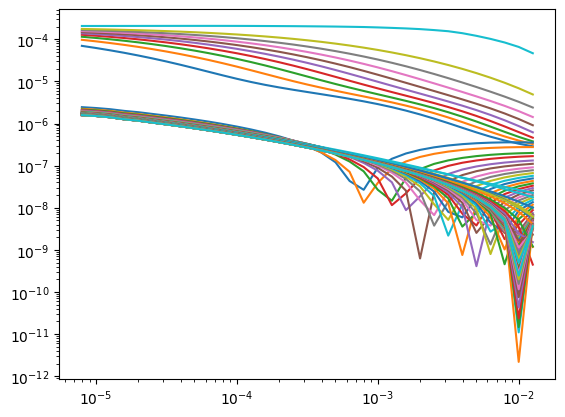

In [15]:
plt.figure()
plt.loglog(t1.numpy(), np.abs(dbdt1.numpy().real))

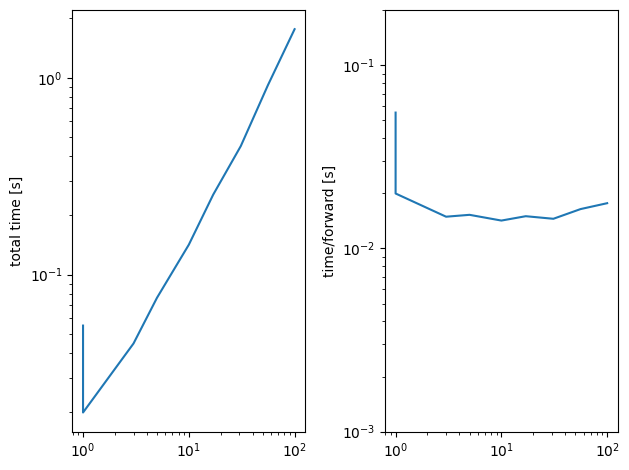

In [11]:
fig,axs = plt.subplots(1,2)
axs[0].loglog(n_forwards, t_forwards);            axs[0].set_ylabel('total time [s]')
axs[1].loglog(n_forwards, t_forwards/n_forwards); axs[1].set_ylabel('time/forward [s]')
axs[1].set_ylim(0.001, 0.2)
plt.tight_layout()

so appears to be at the machine precision level so that is wonderful.